### Astrostatistics lecture 1

Conservative wins: 3270
Switcher wins: 6730
Newcomer wins: 5136


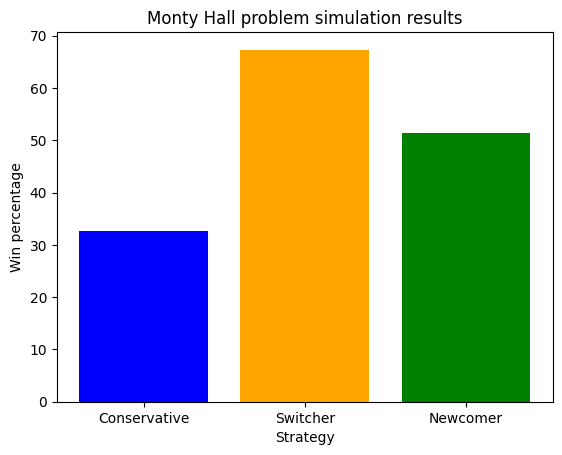

In [ ]:
import random
import numpy as np 
import matplotlib.pyplot as plt

N=10000
i = 0
c_win = 0
s_win = 0
n_win = 0

my_array = [0, 0, 1]
#print("original array:", my_array, "\n")

while i < N:
    #we shuffle the array to randomize the order of the entries
    random.shuffle(my_array)
    #print(my_array)
    #record the index of the 1 in the array
    winning_index = np.where(np.array(my_array) == 1)[0][0]
    #print("winning index:", winning_index)

    #then we make the first two pick an index in the array 
    first_pick = random.randint(0, 2)
    #print("picked:", first_pick)

    #eliminate the other index that is not the 1 and not the first pick
    excluded_index  = [i for i in range(3) if i != first_pick and i != winning_index]
    #print("exluded:", excluded_index)
    #In case we have 2 ramaining indices, we randomly eliminate one of them
    if len(excluded_index) > 1:
        eliminated_index = random.choice(excluded_index)
        #print("eliminated index:", eliminated_index)
        #the switcher changes to the other index
        switcher_pick = [i for i in range(3) if i != first_pick and i != eliminated_index][0]
        #print("switcher pick:", switcher_pick)
        #the third option, the newcomer, randomly picks one of the remaining indices
        newcomer_pick = random.choice([i for i in range(3) if i != eliminated_index])
        #print("newcomer pick:", newcomer_pick)
    else :
        switcher_pick = [i for i in range(3) if i != first_pick and i != excluded_index[0]][0]
        #print("switcher pick:", switcher_pick)
        newcomer_pick = random.choice([i for i in range(3) if i != excluded_index[0]])
        #print("newcomer pick:", newcomer_pick)

    #the conservative doesn't change the first pick
    conservative_pick = first_pick
    #print("conservative pick:", conservative_pick , "\n")

    #finally we check if the picks are correct
    if conservative_pick == winning_index:
        c_win += 1
    if switcher_pick == winning_index:
        s_win += 1
    if newcomer_pick == winning_index:
        n_win += 1
    i += 1
print("Conservative wins:", c_win)
print("Switcher wins:", s_win)
print("Newcomer wins:", n_win)

plt.bar(['Conservative', 'Switcher', 'Newcomer'], [100*c_win/N, 100*s_win/N, 100*n_win/N], color=['blue', 'orange', 'green'])
plt.xlabel('Strategy')
plt.ylabel('Win percentage')
plt.title('Monty Hall problem simulation results')
plt.show()


### N doors case 

[40, 50, 60, 70, 80, 85, 90, 93, 95, 97, 98]
Doors opened= 40 | cons   0.9% | switch   1.8% | new   1.5%
Doors opened= 50 | cons   0.9% | switch   2.2% | new   1.7%
Doors opened= 60 | cons   0.9% | switch   2.6% | new   2.5%
Doors opened= 70 | cons   0.9% | switch   3.7% | new   3.7%
Doors opened= 80 | cons   0.9% | switch   5.4% | new   4.3%
Doors opened= 85 | cons   0.9% | switch   7.3% | new   7.0%
Doors opened= 90 | cons   1.3% | switch  10.6% | new  10.2%
Doors opened= 93 | cons   1.1% | switch  16.2% | new  14.8%
Doors opened= 95 | cons   0.8% | switch  25.1% | new  20.3%
Doors opened= 97 | cons   1.1% | switch  50.3% | new  33.1%
Doors opened= 98 | cons   1.1% | switch  98.9% | new  50.0%


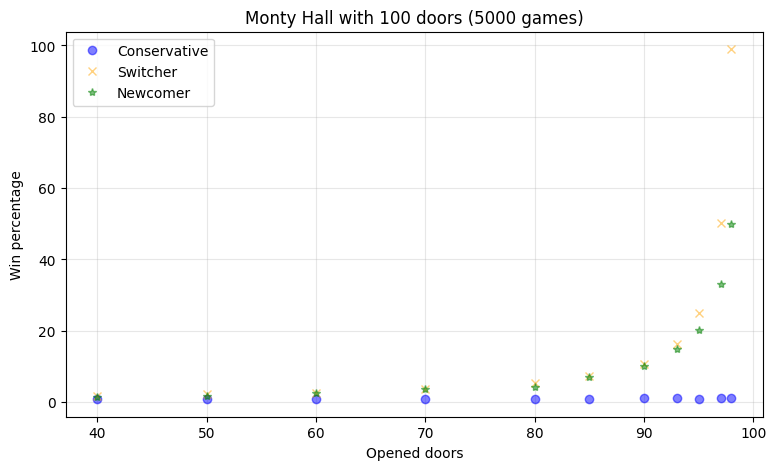

In [67]:
import random
import numpy as np
import matplotlib.pyplot as plt

n_doors = 100    #don't put under 100 (il 98% di porte aperte sennò non funziona)
N = 5000  # number of games
P_percentage = [40, 50, 60, 70, 80, 85, 90, 93, 95, 97, 98]  # number of doors opened, each game is done with every P
P_values = [int(p / 100 * n_doors) for p in P_percentage]
print(P_values)

def play(n_doors, P):   
    winning = random.randrange(n_doors)
    first_pick = random.randrange(n_doors)

    #open P doors that are not the first pick or the winning one and eliminate them
    candidates = [d for d in range(n_doors) if d != first_pick and d != winning]
    eliminated = set(random.sample(candidates, P))
    remaining = [d for d in range(n_doors) if d not in eliminated]

    conservative = first_pick #keep the first
    switcher = random.choice([d for d in remaining if d != first_pick]) #switch among the remaining
    newcomer = random.choice(remaining) #random pick among the remaining

    return conservative == winning, switcher == winning, newcomer == winning

c_rates, s_rates, n_rates = [], [], []

for P in P_values:
    c = s = n = 0
    for _ in range(N):
        wc, ws, wn = play(n_doors, P)   #play the game
        c += wc
        s += ws
        n += wn
    c_rates.append(100 * c / N)
    s_rates.append(100 * s / N)
    n_rates.append(100 * n / N)
    print(f"Doors opened={P:3d} | cons {c_rates[-1]:5.1f}% | switch {s_rates[-1]:5.1f}% | new {n_rates[-1]:5.1f}%")


plt.figure(figsize=(9, 5))
plt.plot(P_values, c_rates, 'o', color='blue', label='Conservative', alpha=0.5)
plt.plot(P_values, s_rates, 'x', color='orange', label='Switcher', alpha=0.5)
plt.plot(P_values, n_rates, '*', color='green', label='Newcomer', alpha=0.5)
plt.xlabel('Opened doors')
plt.ylabel('Win percentage')
plt.title(f'Monty Hall with {n_doors} doors ({N} games)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()